In [31]:
import cv2
import os 
import matplotlib
import yaml

import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt

from matplotlib import gridspec
from matplotlib.collections import LineCollection
from aniposelib.cameras import Camera, CameraGroup

matplotlib.rcParams.update({
    'font.family': 'STIXGeneral',
    'mathtext.fontset': 'stix',
})

In [23]:
video_prefix = '/home/ruppk2@hhmi.org/posetail/paper_figures/rat7m_movement/s5-d1__101500__670/rendered'
data_prefix = '/groups/karashchuk/karashchuklab/animal-datasets-processed/posetail-finetuning-v6/rat7m/test/s5-d1/101500/'
pose_path = os.path.join(data_prefix, 'pose3d.npz')
metadata_path = os.path.join(data_prefix, 'metadata.yaml')
data = np.load(pose_path)['pose']
outpath = '/home/ruppk2@hhmi.org/tracktail-paper/figures/v1'

In [33]:
def generate_colors_rgb(n):   # same hues as render_video.generate_colors
    cols = []
    for i in range(n):
        hsv = np.array([[[int(180 * i / n), 255, 255]]], dtype=np.uint8)
        cols.append(tuple(cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)[0, 0] / 255.0))
    return cols

def read_frame(path, idx):
    cap = cv2.VideoCapture(path)
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ret, img = cap.read()
    cap.release()
    if not ret:
        raise RuntimeError(f'Could not read frame {idx} from {path}')
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


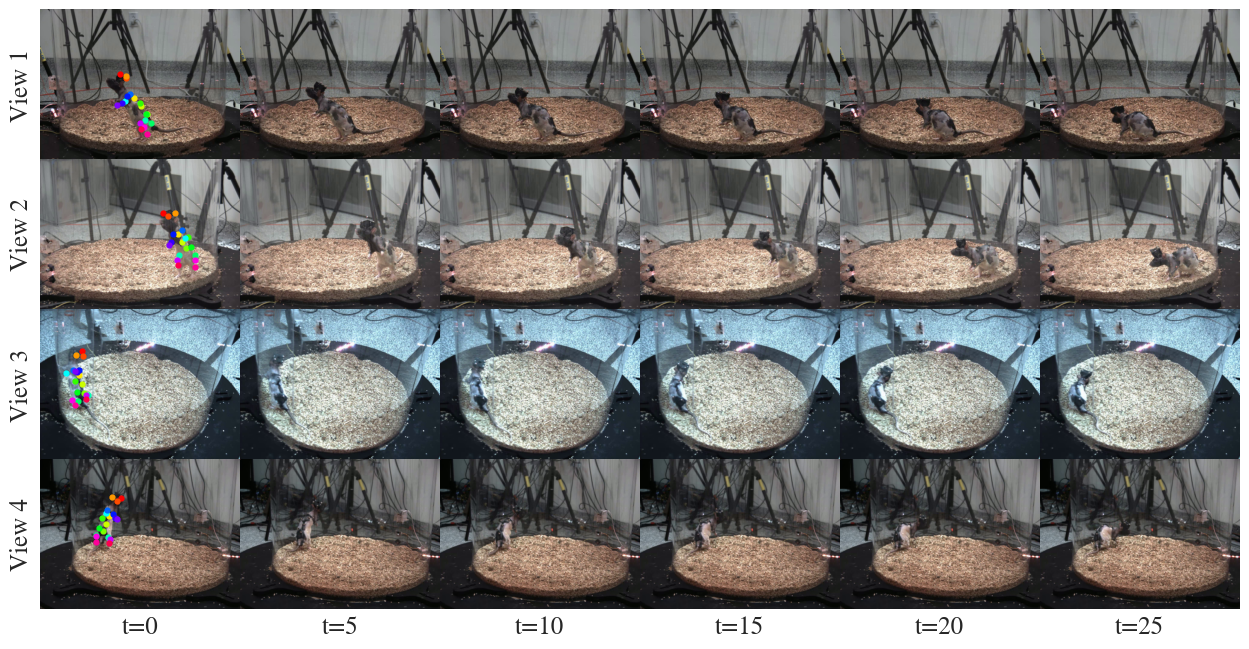

In [29]:
# subplots for 3dpop fig 1 - rgbs from multiple views (rows) for multiple frames (cols)
sns.set_style('ticks', {'font.family': 'STIXGeneral'})
fs = 18

views = ['camera1', 'camera2', 'camera3', 'camera4']
views_labels = ['View 1', 'View 2', 'View 3', 'View 4']
frames = [670, 675, 680, 685, 690, 695]
frames_labels = np.array(frames) - frames[0]

fig, axs = plt.subplots(len(views), len(frames), figsize = (12, 6), 
                        gridspec_kw = {'hspace': 0, 'wspace': 0})

m = yaml.safe_load(open(os.path.join(data_prefix, 'metadata.yaml')))

cams = []
for n in views:
    E = np.asarray(m['extrinsic_matrices'][n], dtype=float)
    rvec, _ = cv2.Rodrigues(E[:3, :3])
    cams.append(Camera(matrix=np.asarray(m['intrinsic_matrices'][n], dtype=float),
                       dist=np.asarray(m['distortion_matrices'][n], dtype=float),
                       rvec=rvec.ravel(), tvec=E[:3, 3], name=n))
cgroup = CameraGroup(cams)

pose0 = data[0, frames[0]]                                   # (N, 3)
p2d0 = cgroup.project(pose0).reshape(len(views), -1, 2)      # (n_cams, N, 2)
colors = generate_colors_rgb(pose0.shape[0])

for i, view in enumerate(views):
    for j, frame in enumerate(frames): 

        ax = axs[i, j]

        vid_path = os.path.join(data_prefix, 'vid', f'{view}.mp4')
        cap = cv2.VideoCapture(vid_path)
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame)
        ret, img = cap.read()
        cap.release()

        if not ret:
            raise RuntimeError(f'Could not read frame {frame} from {vid_path}')
        
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        ax.imshow(img, aspect = 'auto')

        if j == 0:
            for k, c in enumerate(colors):
                ax.scatter(p2d0[i, k, 0], p2d0[i, k, 1], s=12, color=[c], zorder=3)
            ax.set_xlim(0, img.shape[1]); ax.set_ylim(img.shape[0], 0)

        ax.set_xticks([])
        ax.set_yticks([])

        if i == len(views) - 1: 
            ax.set_xlabel(f"t={frames_labels[j]}", fontsize = fs)
        if j == 0: 
            ax.set_ylabel(f"{views_labels[i]}", fontsize = fs)

# plt.tight_layout()

for row in axs:
    for ax in row:
        for spine in ax.spines.values():
            spine.set_visible(False)

outdir = os.path.dirname(outpath)
if outdir:
    os.makedirs(outdir, exist_ok=True)

fig.subplots_adjust(hspace=0, wspace=0, top=1, bottom=0, left=0, right=1)
fig.savefig(os.path.join(outpath, 'rat7m_examples.pdf'), dpi=800, bbox_inches='tight')   

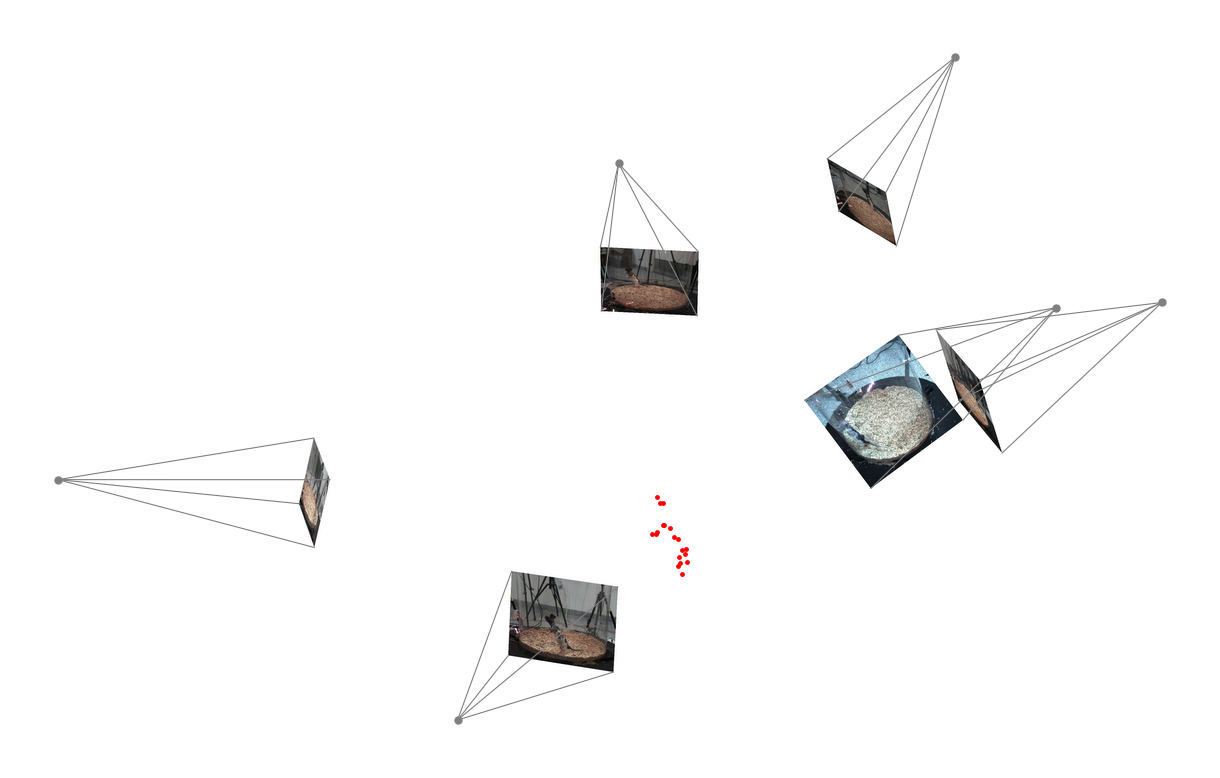

In [ ]:
frame = 670
# depth = 1400            # camera -> image plane distance (mm). Larger = bigger images, longer frustums
cam_dist = 1500                 # ~ camera-to-subject distance for this rig (mm)
depth = 0.4 * cam_dist          # 0.3–0.5 keeps the images apart, between each camera and the animal
azim, elev = -60, 25    # viewing direction of the virtual camera, in degrees
up = (0, 0, 1)          # which world axis is "up"
canvas_w = 2400         # output width in pixels
margin = 0.04           # white border, as a fraction of the width
ss = 2                  # supersampling factor for smoother edges
frustum_color = '0.5'    # gray; use '0.7' for lighter, '0.3' for darker

views = ['camera1', 'camera2', 'camera3', 'camera4', 'camera5', 'camera6']
# views = ['camera1', 'camera2', 'camera3', 'camera4']   # swap in a subset when you want one


def read_frame_rgb(path, idx):
    cap = cv2.VideoCapture(path); cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ok, img = cap.read(); cap.release()
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# ---- one plane per camera: undistorted image placed `depth` in front of the camera ----
planes = []
for n in views:
    E = np.asarray(m['extrinsic_matrices'][n], dtype=float); R, t = E[:3, :3], E[:3, 3]
    K = np.asarray(m['intrinsic_matrices'][n], dtype=float)
    dist = np.asarray(m['distortion_matrices'][n], dtype=float)
    img = read_frame_rgb(os.path.join(data_prefix, 'vid', f'{n}.mp4'), frame)
    h, w = img.shape[:2]
    img = cv2.undistort(img, K, dist)                                   # plain pinhole image, same K
    corners_px = np.array([[0, 0], [w, 0], [w, h], [0, h]], float)
    Xc = np.c_[(corners_px - K[:2, 2]) / np.diag(K)[:2], np.ones(4)] * depth
    planes.append(dict(img=img, corners_px=corners_px,
                       corners_w=(Xc - t) @ R,                         # R^T (Xc - t)
                       center=-R.T @ t))

pose = data[0, frame]
allp = np.concatenate([p['corners_w'] for p in planes]
                      + [np.array([p['center'] for p in planes]), pose[np.isfinite(pose).all(1)]])

# ---- virtual camera that looks at the scene and zooms to fit ----
target = allp.mean(0); radius = np.linalg.norm(allp - target, axis=1).max()
a, e = np.deg2rad(azim), np.deg2rad(elev)
eye = target + 3 * radius * np.array([np.cos(e) * np.cos(a), np.cos(e) * np.sin(a), np.sin(e)])
zc = (target - eye) / np.linalg.norm(target - eye)
xc = np.cross(zc, up); xc /= np.linalg.norm(xc)
yc = np.cross(zc, xc)
Rv = np.stack([xc, yc, zc])

def normalized(X):
    c = (X - eye) @ Rv.T
    return c[:, :2] / c[:, 2:3]

q = normalized(allp); lo, hi = q.min(0), q.max(0)
f = canvas_w * ss * (1 - 2 * margin) / (hi - lo)[0]
Wc = canvas_w * ss
Hc = int(round((hi - lo)[1] * f + 2 * margin * Wc))
c0 = np.array([Wc / 2, Hc / 2]) - f * (lo + hi) / 2
project = lambda X: normalized(X) * f + c0

# ---- warp each plane into the view and composite, farthest first ----
canvas = np.ones((Hc, Wc, 3), np.float32)
depth_in_view = [((p['corners_w'].mean(0) - eye) @ zc) for p in planes]
for i in np.argsort(depth_in_view)[::-1]:
    p = planes[i]
    Hm = cv2.getPerspectiveTransform(p['corners_px'].astype(np.float32),
                                     project(p['corners_w']).astype(np.float32))
    warped = cv2.warpPerspective(p['img'].astype(np.float32) / 255, Hm, (Wc, Hc), flags=cv2.INTER_LINEAR)
    mask = cv2.warpPerspective(np.ones(p['img'].shape[:2], np.float32), Hm, (Wc, Hc),
                               flags=cv2.INTER_LINEAR)[..., None]
    canvas = canvas * (1 - mask) + warped * mask

    
canvas = cv2.resize(canvas, (Wc // ss, Hc // ss), interpolation=cv2.INTER_AREA)

# ---- overlays drawn in matplotlib (crisp) ----
fig = plt.figure(figsize=(canvas.shape[1] / 200, canvas.shape[0] / 200))
ax = fig.add_axes([0, 0, 1, 1])
ax.imshow(canvas, interpolation='lanczos'); ax.set_axis_off()
for p in planes:
    C = project(p['center'][None])[0] / ss
    for corner in project(p['corners_w']) / ss:
        ax.plot([C[0], corner[0]], [C[1], corner[1]], color=frustum_color, lw=0.8)   # frustum edges
    ax.scatter(*C, color=frustum_color, s=25, zorder=4)                              # camera center
P = project(pose[np.isfinite(pose).all(1)]) / ss
ax.scatter(P[:, 0], P[:, 1], s=6, color='r', zorder=5)                      # animal pose
ax.set_xlim(0, canvas.shape[1]); ax.set_ylim(canvas.shape[0], 0)

fig.savefig(os.path.join(outpath, 'rat7m_camera_frustums.pdf'), dpi=800)


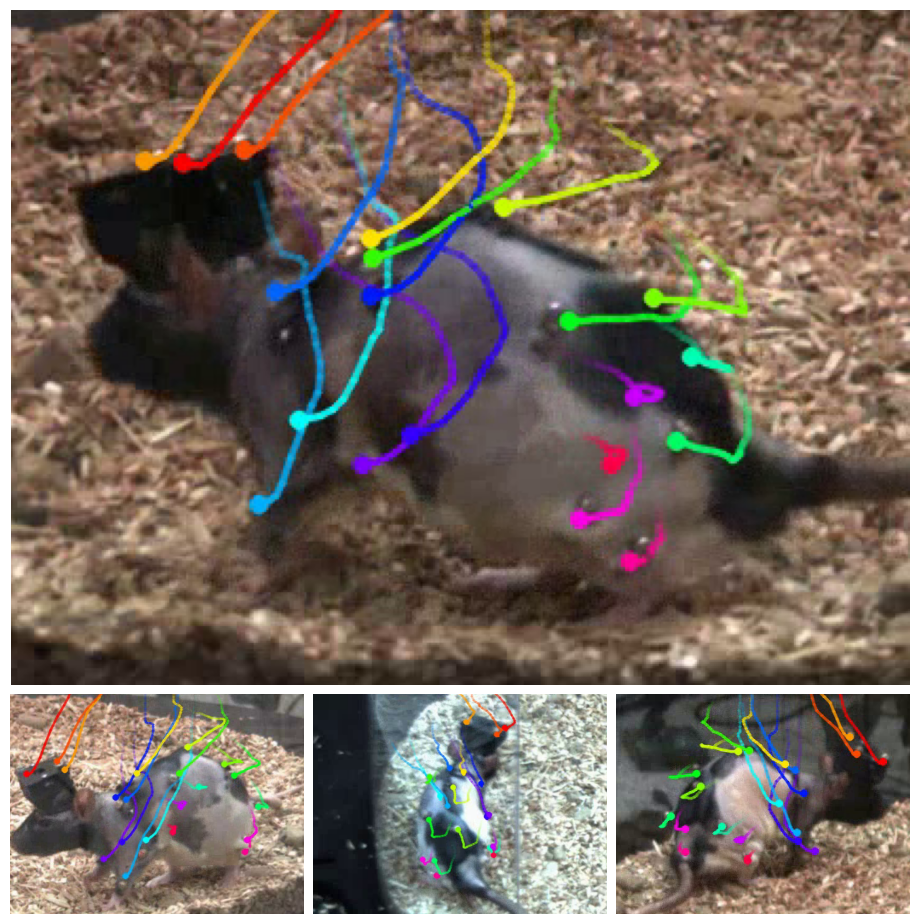

In [49]:
video_prefix = '/home/ruppk2@hhmi.org/posetail/paper_figures/rat7m_movement/s5-d1__101500__670/rendered'

main_cam = 'camera1'
small_cams = ['camera2', 'camera3', 'camera4']
all_cams = [main_cam] + small_cams

frame_idx = 30           # index within the rendered video (0 = original frame 670)
start_frame = 670        # ground-truth frame that rendered frame 0 corresponds to
crop = True
pad = 60                 # pixels around the tracked points
crop_ar = 4 / 3          # width / height of every crop (None = natural bbox shape)
fs = 18

# ---- cameras (for projecting ground truth to find the crop) ----
m = yaml.safe_load(open(os.path.join(data_prefix, 'metadata.yaml')))
cams = []
for n in all_cams:
    E = np.asarray(m['extrinsic_matrices'][n], dtype=float)
    rvec, _ = cv2.Rodrigues(E[:3, :3])
    cams.append(Camera(matrix=np.asarray(m['intrinsic_matrices'][n], dtype=float),
                       dist=np.asarray(m['distortion_matrices'][n], dtype=float),
                       rvec=rvec.ravel(), tvec=E[:3, 3], name=n))
cgroup = CameraGroup(cams)

# ---- helpers ----
def read_frame(path, idx):
    cap = cv2.VideoCapture(path)
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ret, img = cap.read()
    cap.release()
    if not ret:
        raise RuntimeError(f'Could not read frame {idx} from {path}')
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def crop_box(cam_idx, gt_frame, img_w, img_h):
    pts = cgroup.project(data[0, gt_frame]).reshape(len(all_cams), -1, 2)[cam_idx]
    pts = pts[np.isfinite(pts).all(1)]
    x0, y0 = pts.min(0) - pad
    x1, y1 = pts.max(0) + pad
    if crop_ar is not None:                      # grow the shorter side to hit the aspect ratio
        w, h = x1 - x0, y1 - y0
        if w / h < crop_ar:
            cx = (x0 + x1) / 2; w = h * crop_ar; x0, x1 = cx - w / 2, cx + w / 2
        else:
            cy = (y0 + y1) / 2; h = w / crop_ar; y0, y1 = cy - h / 2, cy + h / 2
    w, h = min(x1 - x0, img_w), min(y1 - y0, img_h)   # clamp size, then shift inside the image
    x0 = np.clip(x0, 0, img_w - w); y0 = np.clip(y0, 0, img_h - h)
    return int(x0), int(y0), int(x0 + w), int(y0 + h)

def show(ax, cam, title_fs):
    img = read_frame(os.path.join(video_prefix, f'{cam}.mp4'), frame_idx)
    if crop:
        h, w = img.shape[:2]
        x0, y0, x1, y1 = crop_box(all_cams.index(cam), start_frame + frame_idx, w, h)
        img = img[y0:y1, x0:x1]
    ax.imshow(img)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    # ax.set_title(cam, fontsize=title_fs)

# ---- figure: one big view over three small views ----
sns.set_style('ticks', {'font.family': 'STIXGeneral'})

W = 9           # figure width in inches
g = 0.01        # gap between panels, as a fraction of the figure width
r = crop_ar     # image aspect (width / height) -- must match the crop

small_w = (1 - 2 * g) / 3                  # width of each small panel
H = 1 / r + g + small_w / r                # total height, in units of figure width

fig = plt.figure(figsize=(W, W * H))

# big view: full width, at the top
ax_main = fig.add_axes([0, (g + small_w / r) / H, 1, (1 / r) / H])

# three small views along the bottom
axs_small = [fig.add_axes([c * (small_w + g), 0, small_w, (small_w / r) / H])
             for c in range(3)]

show(ax_main, main_cam, fs)
for ax, cam in zip(axs_small, small_cams):
    show(ax, cam, fs - 4)

fig.savefig(os.path.join(outpath, 'rat7m_with_tracks.pdf'), dpi=800, bbox_inches='tight')


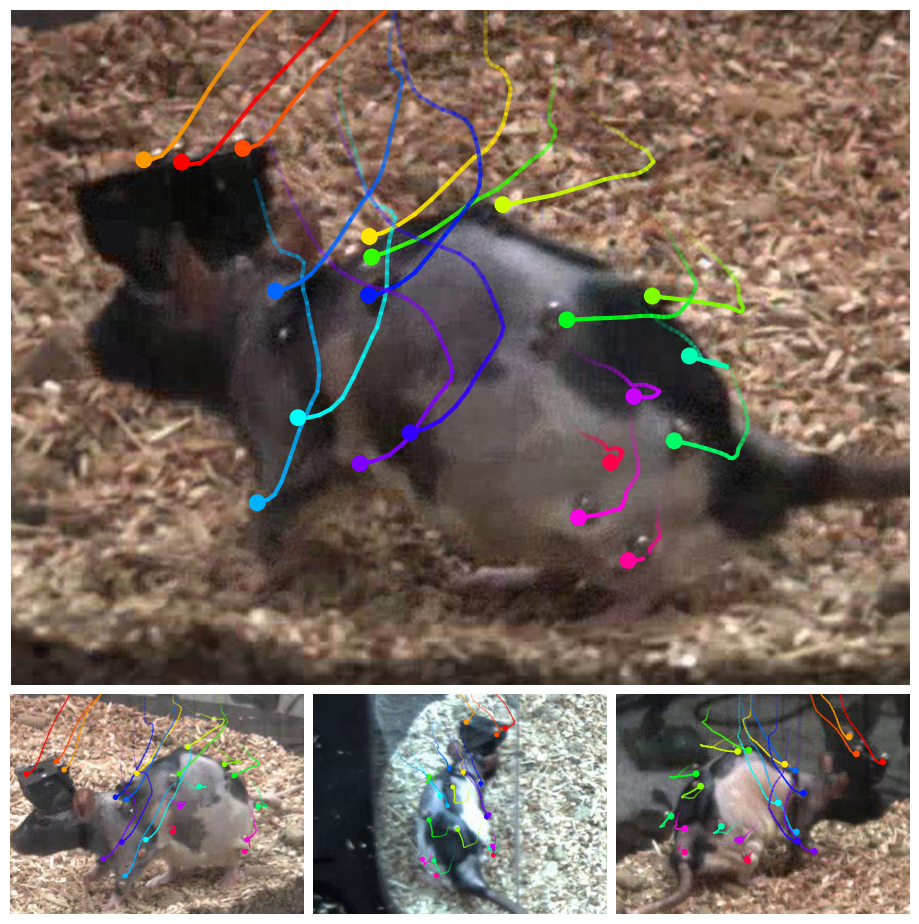

In [ ]:
npz = np.load('/home/ruppk2@hhmi.org/posetail/paper_figures/rat7m_movement/s5-d1__101500__670/output.npz',
              allow_pickle=True)
sig = lambda x: 1 / (1 + np.exp(-x))
pred3d = npz['coords_pred'][0]                        # (T, N, 3)
conf = sig(npz['conf_pred'][0])                       # (T, N)
vis = sig(npz['vis_pred'][0][..., 0])                 # (T, N)
T, N = pred3d.shape[:2]
pred2d = cgroup.project(pred3d.reshape(-1, 3)).reshape(len(all_cams), T, N, 2)
colors = generate_colors_rgb(N)                       # from earlier (same hues as render_video)

orig_vid_dir = os.path.join(data_prefix, 'vid')

marker_r = 4         # marker radius in IMAGE pixels (render_video's marker_size)
trail_px = 2         # trail line width in IMAGE pixels
trail_len = 30       # number of past frames in the trail (0 = no trail)
conf_thr = 0.5

# ---- CHANGED: new show() ----
def show(ax, cam, title_fs):
    ci = all_cams.index(cam)
    t = frame_idx
    img = read_frame(os.path.join(orig_vid_dir, f'{cam}.mp4'), start_frame + t)
    h, w = img.shape[:2]
    x0, y0, x1, y1 = crop_box(ci, start_frame + t, w, h) if crop else (0, 0, w, h)

    ax.imshow(img, interpolation='lanczos')
    ax.set_xlim(x0, x1); ax.set_ylim(y1, y0)

    # points per image pixel for THIS panel, so sizes match across panels
    pos = ax.get_position()
    pt_per_px = pos.width * fig.get_figwidth() * 72 / (x1 - x0)

    pts = pred2d[ci]                                              # (T, N, 2)
    good = (conf >= conf_thr) & (vis >= conf_thr) & np.isfinite(pts).all(-1)   # (T, N)

    # trails: one fading segment per consecutive pair of valid points
    t0 = max(0, t - trail_len)
    for k in range(N):
        segs, alphas = [], []
        for s in range(t0, t):
            if good[s, k] and good[s + 1, k]:
                segs.append(pts[s:s + 2, k])
                alphas.append((s - t0 + 1) / max(t - t0, 1))
        if segs:
            rgba = np.array([(*colors[k], a) for a in alphas])
            ax.add_collection(LineCollection(segs, colors=rgba, linewidths=trail_px * pt_per_px,
                                             capstyle='round', zorder=2))

    ks = np.where(good[t])[0]
    ax.scatter(pts[t, ks, 0], pts[t, ks, 1], s=(2 * marker_r * pt_per_px) ** 2,
               c=[colors[k] for k in ks], edgecolors='none', zorder=3)

    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)

# ---- figure: one big view over three small views ----  (UNCHANGED from here down)
sns.set_style('ticks', {'font.family': 'STIXGeneral'})

W = 9           # figure width in inches
g = 0.01        # gap between panels, as a fraction of the figure width
r = crop_ar     # image aspect (width / height) -- must match the crop

small_w = (1 - 2 * g) / 3                  # width of each small panel
H = 1 / r + g + small_w / r                # total height, in units of figure width

fig = plt.figure(figsize=(W, W * H))

# big view: full width, at the top
ax_main = fig.add_axes([0, (g + small_w / r) / H, 1, (1 / r) / H])

# three small views along the bottom
axs_small = [fig.add_axes([c * (small_w + g), 0, small_w, (small_w / r) / H])
             for c in range(3)]

show(ax_main, main_cam, fs)
for ax, cam in zip(axs_small, small_cams):
    show(ax, cam, fs - 4)

fig.savefig(os.path.join(outpath, 'rat7m_with_tracks_highres.pdf'), dpi=800, bbox_inches='tight')
